#  Zero-Shot Paraphrase Identification with Qwen 2.5 7B
## Qwen 2.5 7B Instruct (4-bit, served locally with Ollama on a cluster GPU) is evaluated with no fine-tuning on the full MRPC (408), QQP (5,000) and PAWS (8,000) test sets.

In [5]:
import glob
import pandas as pd
from ollama import Client
import os, socket, json, time, subprocess
from tqdm import tqdm
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report
import numpy as np, shutil
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import precision_recall_fscore_support

In [1]:
print(os.listdir("/scratch/bhandari.ru/paraphrase"))

['out', 'out_team']


## Downloading ollama and connecting to the Ollama Server and Verify the Model
### Checks the node, GPU and loaded model. It fails here if the server is down.

In [2]:
%pip install -q ollama pandas scikit-learn tqdm


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
os.environ["no_proxy"] = "localhost,127.0.0.1,d1013"
from ollama import Client
client = Client(host="http://localhost:11434")
MODEL = "qwen2.5:7b-instruct-q4_K_M"

r = client.chat(model=MODEL, messages=[{"role": "user", "content": "Reply with the word OK"}],
                options={"temperature": 0})
print(r["message"]["content"])

OK


In [6]:
node = socket.gethostname()
os.environ["no_proxy"] = f"localhost,127.0.0.1,{node}"
client = Client(host="http://localhost:11434")

# Server info
models = client.list()
model_names = [m.model for m in models.models]

# GPU info
gpu = subprocess.getoutput("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")

print("=" * 55)
print(f"  Node         : {node}")
print(f"  Ollama host  : http://localhost:11434")
print(f"  GPU          : {gpu.strip()}")
print(f"  Models loaded: {model_names}")
print(f"  Using model  : qwen2.5:7b-instruct-q4_K_M")
print("=" * 55)

node = socket.gethostname()
os.environ["no_proxy"] = f"localhost,127.0.0.1,{node}"
MODEL = "qwen2.5:7b-instruct-q4_K_M"
client = Client(host="http://localhost:11434")

gpu = subprocess.getoutput("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")
print("Node:", node, "| GPU:", gpu.strip())
print("Models:", [m.model for m in client.list().models])   # fails here if the server is down

  Node         : d1013
  Ollama host  : http://localhost:11434
  GPU          : Tesla V100-SXM2-32GB, 32768 MiB
  Models loaded: ['qwen2.5:7b-instruct-q4_K_M']
  Using model  : qwen2.5:7b-instruct-q4_K_M
Node: d1013 | GPU: Tesla V100-SXM2-32GB, 32768 MiB
Models: ['qwen2.5:7b-instruct-q4_K_M']


## Inspecting the Test Splits
### Confirms the file names, columns (`sentence1`, `sentence2`, `label`) and class balance.

In [4]:
print(glob.glob("splits/*"))

['splits/mrpc_dev.csv', 'splits/mrpc_test.csv', 'splits/mrpc_train.csv', 'splits/paws_dev.csv', 'splits/paws_test.csv', 'splits/paws_train.csv', 'splits/qqp_dev.csv', 'splits/qqp_test.csv', 'splits/qqp_train.csv']


In [5]:
for name in ["mrpc", "paws", "qqp"]:
    df = pd.read_csv(f"splits/{name}_test.csv")
    print(name, df.shape)
    print(df.columns.tolist())
    print(df.head(2).to_string(), "\n")
    print(df.iloc[:, -1].value_counts().to_dict() if df.shape[1] else "", "\n")

mrpc (408, 3)
['sentence1', 'sentence2', 'label']
                                                                                                            sentence1                                                                                                               sentence2  label
0                        He said the foodservice pie business doesn 't fit the company 's long-term growth strategy .                                             " The foodservice pie business does not fit our long-term growth strategy .      1
1  Magnarelli said Racicot hated the Iraqi regime and looked forward to using his long years of training in the war .  His wife said he was " 100 percent behind George Bush " and looked forward to using his years of training in the war .      0 

{1: 279, 0: 129} 

paws (8000, 3)
['sentence1', 'sentence2', 'label']
                                                                                                                                               

# LLM Classifier 

## Zero-Shot Classifier
### Prompt, JSON schema and `predict()`. Temperature 0 and seed 42 make the output deterministic. A connection error stops the run immediately.

In [7]:
MODEL = "qwen2.5:7b-instruct-q4_K_M"
client = Client(host="http://localhost:11434")

SYSTEM = (
    "You are a paraphrase detector. Given two sentences, decide whether they "
    "express the same meaning. Answer 'paraphrase' only if all key facts and "
    "relations are preserved; otherwise 'not_paraphrase'. "
    'Respond only with valid JSON: {"label": "paraphrase"} or {"label": "not_paraphrase"}.'
)
SCHEMA = {
    "type": "object",
    "properties": {"label": {"type": "string", "enum": ["paraphrase", "not_paraphrase"]}},
    "required": ["label"],
}
last_error = None

def predict(s1, s2, retries=3):
    global last_error
    for _ in range(retries):
        try:
            r = client.chat(
                model=MODEL,
                messages=[{"role": "system", "content": SYSTEM},
                          {"role": "user", "content": f"Sentence 1: {s1}\nSentence 2: {s2}"}],
                format=SCHEMA,
                options={"temperature": 0.0, "seed": 42, "num_ctx": 2048, "num_predict": 20},
            )
            return 1 if json.loads(r["message"]["content"])["label"] == "paraphrase" else 0
        except ConnectionError as e:
            raise RuntimeError(f"Ollama server is down: {e}")   # stop immediately
        except Exception as e:
            last_error = repr(e)
            time.sleep(1)
    return -1

## Output Folder and Helper Functions

In [8]:
OUT_DIR = "qwen_results"
os.makedirs(OUT_DIR, exist_ok=True)

### `run_dataset()` runs a full test set with checkpointing. 

In [9]:
def run_dataset(name, expected_rows):
    df = pd.read_csv(f"splits/{name}_test.csv")
    assert len(df) == expected_rows, f"{name}: got {len(df)} rows"
    partial = f"{OUT_DIR}/qwen_{name}_partial.csv"
    preds = pd.read_csv(partial)["pred"].tolist() if os.path.exists(partial) else []
    print(f"{name}: {len(df)} rows, resuming from {len(preds)}")
    for i in tqdm(range(len(preds), len(df)), initial=len(preds), total=len(df)):
        preds.append(predict(df.sentence1[i], df.sentence2[i]))
        if len(preds) % 500 == 0:
            pd.DataFrame({"pred": preds}).to_csv(partial, index=False)
    df["qwen_pred"] = preds
    df.to_csv(f"{OUT_DIR}/qwen_{name}_results.csv", index=False)
    return df

### `report()` prints the metrics and confusion matrix.

In [10]:
def report(name, df):
    ok = df[df["qwen_pred"] != -1]
    y, p = ok["label"], ok["qwen_pred"]
    print(f"\n=== {name.upper()} (n={len(df)}, failures={(df['qwen_pred']==-1).sum()}) ===")
    print(f"Accuracy {accuracy_score(y,p):.4f} | Precision {precision_score(y,p):.4f} | "
          f"Recall {recall_score(y,p):.4f} | F1 {f1_score(y,p):.4f}")
    print(confusion_matrix(y, p))

## MRCP

In [11]:
mrpc = run_dataset("mrpc", 408)
report("mrpc", mrpc)

mrpc: 408 rows, resuming from 0


100%|██████████| 408/408 [01:25<00:00,  4.77it/s]



=== MRPC (n=408, failures=0) ===
Accuracy 0.7402 | Precision 0.8531 | Recall 0.7491 | F1 0.7977
[[ 93  36]
 [ 70 209]]


In [12]:
valid = mrpc[mrpc["qwen_pred"] != -1]
y, p = valid["label"], valid["qwen_pred"]

print(f"Accuracy  : {accuracy_score(y, p):.4f}")
print(f"Precision : {precision_score(y, p):.4f}")
print(f"Recall    : {recall_score(y, p):.4f}")
print(f"F1        : {f1_score(y, p):.4f}")
print("\nConfusion matrix (rows=actual, cols=pred):")
print(confusion_matrix(y, p))

Accuracy  : 0.7402
Precision : 0.8531
Recall    : 0.7491
F1        : 0.7977

Confusion matrix (rows=actual, cols=pred):
[[ 93  36]
 [ 70 209]]


## PAWS 

In [13]:
paws = run_dataset("paws", 8000)
report("paws", paws)
print("last_error:", last_error)

paws: 8000 rows, resuming from 0


100%|██████████| 8000/8000 [27:22<00:00,  4.87it/s]



=== PAWS (n=8000, failures=0) ===
Accuracy 0.8485 | Precision 0.7866 | Recall 0.9019 | F1 0.8403
[[3599  865]
 [ 347 3189]]
last_error: None


## QQP

In [14]:
qqp = run_dataset("qqp", 5000)
report("qqp", qqp)
print("last_error:", last_error)

qqp: 5000 rows, resuming from 0


100%|██████████| 5000/5000 [14:33<00:00,  5.72it/s]



=== QQP (n=5000, failures=0) ===
Accuracy 0.8144 | Precision 0.8428 | Recall 0.6076 | F1 0.7061
[[2957  208]
 [ 720 1115]]
last_error: None


## Results Summary
### All three runs used the full test sets with 0 failures: MRPC 0.740, QQP 0.814 and PAWS 0.849 accuracy.

In [15]:
rows = []
for n, d in [("MRPC", mrpc), ("QQP", qqp), ("PAWS", paws)]:
    ok = d[d["qwen_pred"] != -1]
    rows.append({"Dataset": n, "n": len(d), "failures": int((d["qwen_pred"] == -1).sum()),
                 "Accuracy": round(accuracy_score(ok["label"], ok["qwen_pred"]), 4),
                 "F1": round(f1_score(ok["label"], ok["qwen_pred"]), 4)})
summary = pd.DataFrame(rows)
summary.to_csv(f"{OUT_DIR}/qwen_final_summary.csv", index=False)
print(summary.to_string(index=False))

Dataset    n  failures  Accuracy     F1
   MRPC  408         0    0.7402 0.7977
    QQP 5000         0    0.8144 0.7061
   PAWS 8000         0    0.8485 0.8403


## Saving Predictions
### Saves `.npy` prediction files and a zip backup so results can be reused without rerunning Qwen.

In [16]:
for name, d in [("mrpc", mrpc), ("qqp", qqp), ("paws", paws)]:
    np.save(f"{OUT_DIR}/qwen_{name}_preds.npy", d["qwen_pred"].values)
shutil.make_archive("qwen_results_backup", "zip", OUT_DIR)
print(os.listdir(OUT_DIR))

['qwen_final_summary.csv', 'qwen_mrpc_preds.npy', 'qwen_mrpc_results.csv', 'qwen_paws_partial.csv', 'qwen_paws_preds.npy', 'qwen_paws_results.csv', 'qwen_qqp_partial.csv', 'qwen_qqp_preds.npy', 'qwen_qqp_results.csv']


## Error Analysis: Confusion Matrices and Per-Class Metrics

In [17]:
for name in ["mrpc", "qqp", "paws"]:
    d = pd.read_csv(f"qwen_results/qwen_{name}_results.csv")
    d = d[d["qwen_pred"] != -1]
    cm = confusion_matrix(d["label"], d["qwen_pred"])
    tn, fp, fn, tp = cm.ravel()
    print(f"\n===== {name.upper()} (n={len(d)}) =====")
    print(pd.DataFrame(cm, index=["actual not_para", "actual para"], columns=["pred not_para", "pred para"]))
    print(f"False positive rate: {fp/(fp+tn):.1%} | Miss rate (FN): {fn/(fn+tp):.1%}")
    print(f"Predicted 'paraphrase': {(tp+fp)/len(d):.1%} | Actual 'paraphrase': {(tp+fn)/len(d):.1%}")
    print(classification_report(d["label"], d["qwen_pred"], target_names=["not_para", "para"], digits=3))


===== MRPC (n=408) =====
                 pred not_para  pred para
actual not_para             93         36
actual para                 70        209
False positive rate: 27.9% | Miss rate (FN): 25.1%
Predicted 'paraphrase': 60.0% | Actual 'paraphrase': 68.4%
              precision    recall  f1-score   support

    not_para      0.571     0.721     0.637       129
        para      0.853     0.749     0.798       279

    accuracy                          0.740       408
   macro avg      0.712     0.735     0.717       408
weighted avg      0.764     0.740     0.747       408


===== QQP (n=5000) =====
                 pred not_para  pred para
actual not_para           2957        208
actual para                720       1115
False positive rate: 6.6% | Miss rate (FN): 39.2%
Predicted 'paraphrase': 26.5% | Actual 'paraphrase': 36.7%
              precision    recall  f1-score   support

    not_para      0.804     0.934     0.864      3165
        para      0.843     0.608     0.7

# Visualizations 

In [6]:
OUT_DIR = "qwen_results"; FIG = f"{OUT_DIR}/figures"; os.makedirs(FIG, exist_ok=True)
names = ["mrpc", "qqp", "paws"]; LAB = {"mrpc": "MRPC", "qqp": "QQP", "paws": "PAWS"}
COL = {"mrpc": "#d95f02", "qqp": "#7570b3", "paws": "#1b9e77"}

D = {}
for n in names:
    d = pd.read_csv(f"{OUT_DIR}/qwen_{n}_results.csv")
    D[n] = d[d.qwen_pred != -1].reset_index(drop=True)          # 0 failures expected
maj = {n: max(D[n].label.mean(), 1 - D[n].label.mean()) for n in names}

# per-dataset metrics
M, PCR = {}, {}
for n in names:
    y, p = D[n].label.values, D[n].qwen_pred.values
    pr, rc, f, _ = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    PCR[n] = (pr, rc, f)
    M[LAB[n]] = {"Accuracy": accuracy_score(y, p), "Precision (para)": pr[1],
                 "Recall (para)": rc[1], "F1 (para)": f[1], "Macro-F1": f.mean()}
M = pd.DataFrame(M)


## Metrics Heatmap
### Accuracy, precision, recall, F1 and macro-F1 for each test set. PAWS is the strongest (macro-F1 0.848), QQP is next (0.785) and MRPC is the weakest (0.717). QQP's paraphrase recall (0.608) is the lowest cell in the table.

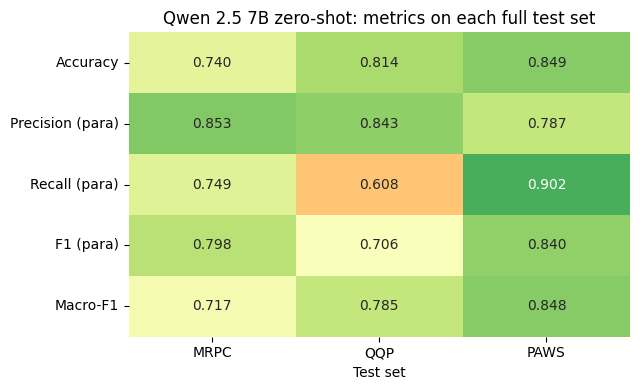

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(M, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.4, vmax=1, cbar=False, ax=ax)
ax.set_title("Qwen 2.5 7B zero-shot: metrics on each full test set"); ax.set_xlabel("Test set")
plt.tight_layout(); plt.savefig(f"{FIG}/1_qwen_metrics_heatmap.png", dpi=200); plt.show()

## Accuracy vs. Majority-Class Baseline
### Qwen beats always guessing the majority class on every dataset: 0.740 vs 0.684 on MRPC, 0.814 vs 0.633 on QQP and 0.849 vs 0.558 on PAWS. The largest margin is on PAWS. Error bars are 95% bootstrap intervals, since Qwen has one deterministic run instead of multiple seeds.

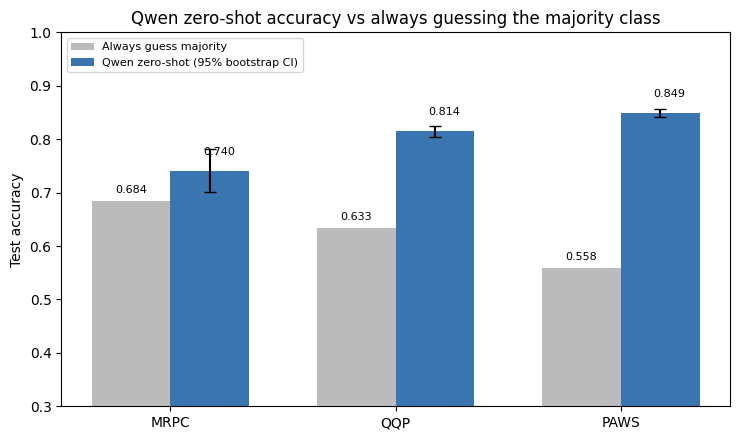

In [8]:
rng = np.random.default_rng(42)
def boot_ci(y, p, B=1000):
    idx = rng.integers(0, len(y), (B, len(y)))
    return np.percentile((y[idx] == p[idx]).mean(1), [2.5, 97.5])

acc = [M[LAB[n]]["Accuracy"] for n in names]
ci = [boot_ci(D[n].label.values, D[n].qwen_pred.values) for n in names]
err = [[a - c[0] for a, c in zip(acc, ci)], [c[1] - a for a, c in zip(acc, ci)]]
x = np.arange(3); w = 0.35
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(x - w/2, [maj[n] for n in names], w, label="Always guess majority", color="#bbbbbb")
ax.bar(x + w/2, acc, w, yerr=err, capsize=4, label="Qwen zero-shot (95% bootstrap CI)", color="#3b75af")
for xi, v in zip(x - w/2, [maj[n] for n in names]): ax.text(xi, v + 0.015, f"{v:.3f}", ha="center", fontsize=8)
for xi, v in zip(x + w/2, acc): ax.text(xi + 0.04, v + 0.03, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([LAB[n] for n in names]); ax.set_ylim(0.3, 1.0)
ax.set_ylabel("Test accuracy"); ax.set_title("Qwen zero-shot accuracy vs always guessing the majority class")
ax.legend(loc="upper left", fontsize=8); plt.tight_layout()
plt.savefig(f"{FIG}/2_qwen_accuracy_vs_majority.png", dpi=200); plt.show()

## Confusion Matrices
### Percentage of each true class predicted as each label. MRPC errors are balanced (about 28% and 25%). QQP errors are almost all missed paraphrases, and PAWS errors are mostly non-paraphrases called paraphrases.

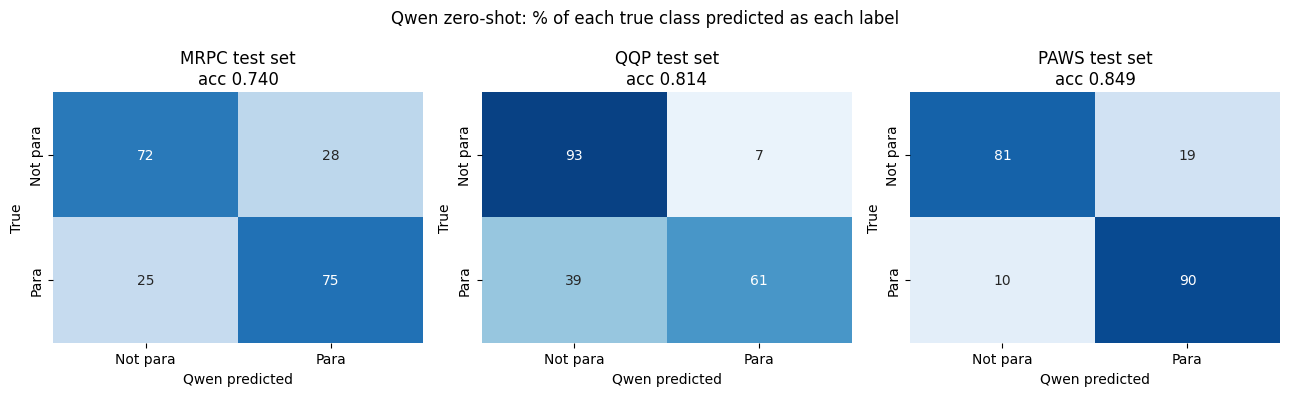

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, n in zip(ax, names):
    cm = confusion_matrix(D[n].label, D[n].qwen_pred, normalize="true") * 100
    sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=a,
                xticklabels=["Not para", "Para"], yticklabels=["Not para", "Para"])
    a.set_title(f"{LAB[n]} test set\nacc {M[LAB[n]]['Accuracy']:.3f}"); a.set_xlabel("Qwen predicted"); a.set_ylabel("True")
plt.suptitle("Qwen zero-shot: % of each true class predicted as each label")
plt.tight_layout(); plt.savefig(f"{FIG}/3_qwen_confusion.png", dpi=200); plt.show()

## Prediction Bias
### How often Qwen says "paraphrase" compared with how often it is true. It under-calls on MRPC (60.0% vs 68.4%) and QQP (26.5% vs 36.7%), and over-calls on PAWS (50.7% vs 44.2%). This is why QQP is conservative and PAWS is lenient.

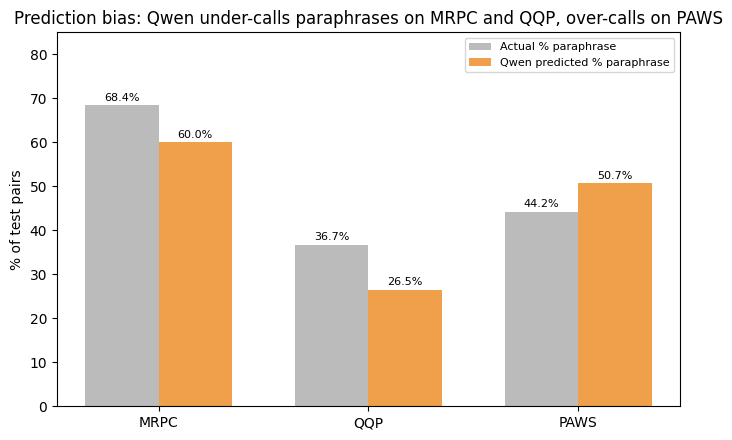

In [11]:
actual = [D[n].label.mean() * 100 for n in names]
pred = [D[n].qwen_pred.mean() * 100 for n in names]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - w/2, actual, w, label="Actual % paraphrase", color="#bbbbbb")
ax.bar(x + w/2, pred, w, label="Qwen predicted % paraphrase", color="#f0a04b")
for xs, vals in [(x - w/2, actual), (x + w/2, pred)]:
    for xi, v in zip(xs, vals): ax.text(xi, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([LAB[n] for n in names]); ax.set_ylim(0, 85)
ax.set_ylabel("% of test pairs"); ax.set_title("Prediction bias: Qwen under-calls paraphrases on MRPC and QQP, over-calls on PAWS")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{FIG}/4_qwen_prediction_bias.png", dpi=200); plt.show()

## Figure 5: Per-Class Precision, Recall and F1

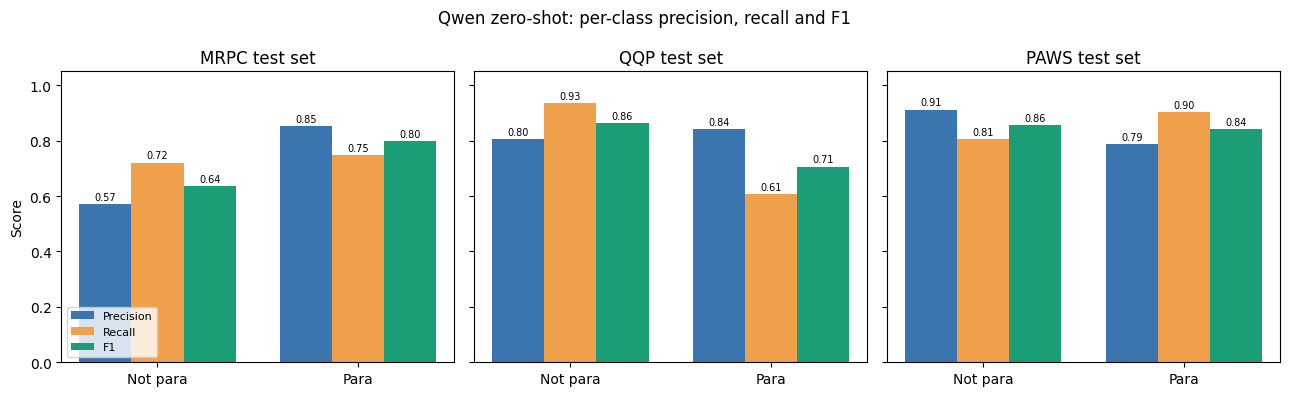

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for a, n in zip(ax, names):
    pr, rc, f = PCR[n]; xx = np.arange(2); bw = 0.26
    for off, vals, lab, c in [(-bw, pr, "Precision", "#3b75af"), (0, rc, "Recall", "#f0a04b"), (bw, f, "F1", "#1b9e77")]:
        a.bar(xx + off, vals, bw, label=lab, color=c)
        for xi, v in zip(xx + off, vals): a.text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=7)
    a.set_xticks(xx); a.set_xticklabels(["Not para", "Para"]); a.set_ylim(0, 1.05); a.set_title(f"{LAB[n]} test set")
ax[0].set_ylabel("Score"); ax[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Qwen zero-shot: per-class precision, recall and F1"); plt.tight_layout()
plt.savefig(f"{FIG}/5_qwen_per_class.png", dpi=200); plt.show()

## Figure 6: Behavior by Word Overlap
### Accuracy and the paraphrase rate as the two sentences share more words. This shows whether Qwen leans on surface overlap, which matters most on PAWS, where unequal pairs share almost all their words.

/tmp/ipykernel_950901/1746700024.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  acc_b = g.apply(lambda t: (t.label == t.qwen_pred).mean()).reindex(bl).where(cnt >= 20)
/tmp/ipykernel_950901/1746700024.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  acc_b = g.apply(lambda t: (t.label == t.qwen_pred).mean()).reindex(bl).where(cnt >= 20)
/tmp/ipykernel_950901/1746700024.py:11: DeprecationWarning: Da

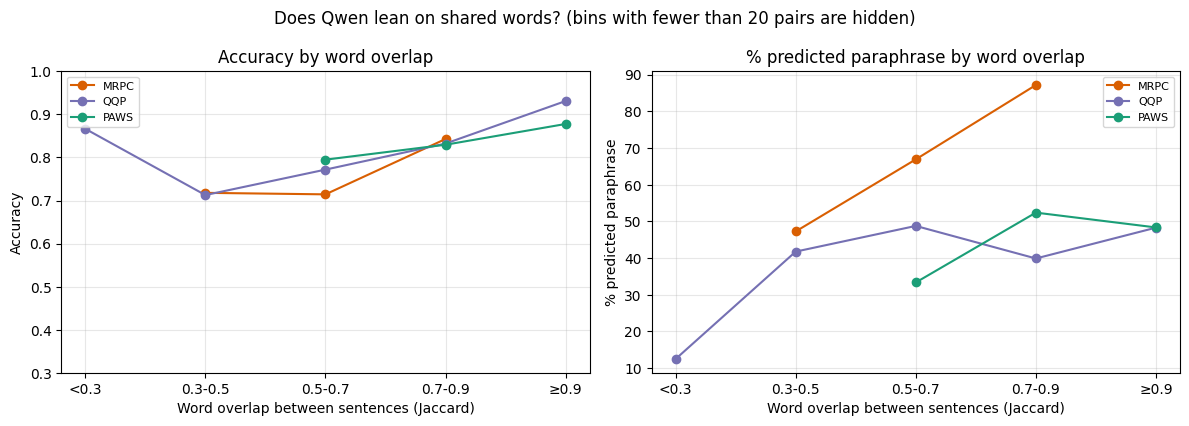

['1_qwen_metrics_heatmap.png', '2_qwen_accuracy_vs_majority.png', '3_qwen_confusion.png', '4_qwen_prediction_bias.png', '5_qwen_per_class.png', '6_qwen_overlap_behavior.png']


In [13]:
def jacc(a, b):
    A, B = set(str(a).lower().split()), set(str(b).lower().split())
    return len(A & B) / max(len(A | B), 1)
bins = [0, .3, .5, .7, .9, 1.0001]; bl = ["<0.3", "0.3-0.5", "0.5-0.7", "0.7-0.9", "≥0.9"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for n in names:
    d = D[n].copy()
    d["ov"] = pd.cut([jacc(a, b) for a, b in zip(d.sentence1, d.sentence2)], bins, labels=bl, include_lowest=True)
    g = d.groupby("ov", observed=True)
    cnt = g.size().reindex(bl)
    acc_b = g.apply(lambda t: (t.label == t.qwen_pred).mean()).reindex(bl).where(cnt >= 20)
    pp_b = g.qwen_pred.mean().reindex(bl).where(cnt >= 20) * 100
    ax[0].plot(bl, acc_b, marker="o", color=COL[n], label=LAB[n])
    ax[1].plot(bl, pp_b, marker="o", color=COL[n], label=LAB[n])
ax[0].set_title("Accuracy by word overlap"); ax[0].set_ylabel("Accuracy"); ax[0].set_ylim(0.3, 1.0)
ax[1].set_title("% predicted paraphrase by word overlap"); ax[1].set_ylabel("% predicted paraphrase")
for a in ax: a.set_xlabel("Word overlap between sentences (Jaccard)"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.suptitle("Does Qwen lean on shared words? (bins with fewer than 20 pairs are hidden)")
plt.tight_layout(); plt.savefig(f"{FIG}/6_qwen_overlap_behavior.png", dpi=200); plt.show()

print(os.listdir(FIG))

## Handwritten Demo
### Ten hand-written pairs covering paraphrases, swapped roles, negation, changed details and unrelated sentences, with Qwen's one-line reason for each. This is an illustration only, since 10 pairs is too few to report as an accuracy figure.

In [20]:
DEMO_SCHEMA = {
    "type": "object",
    "properties": {
        "label": {"type": "string", "enum": ["paraphrase", "not_paraphrase"]},
        "reason": {"type": "string"},
    },
    "required": ["label", "reason"],
}
DEMO_SYSTEM = (
    "You are a paraphrase detector. Decide whether two sentences express the same meaning. "
    "Answer 'paraphrase' only if all key facts and relations are preserved. "
    'Respond only with JSON: {"label": "...", "reason": "<one short sentence>"}.'
)

def demo_predict(s1, s2):
    r = client.chat(
        model=MODEL,
        messages=[{"role": "system", "content": DEMO_SYSTEM},
                  {"role": "user", "content": f"Sentence 1: {s1}\nSentence 2: {s2}"}],
        format=DEMO_SCHEMA,
        options={"temperature": 0.0, "seed": 42, "num_ctx": 2048, "num_predict": 80},
    )
    out = json.loads(r["message"]["content"])
    return out["label"], out["reason"]

pairs = [
    # (sentence1, sentence2, expected label, case type)
    ("The meeting was postponed until next Friday.", "They pushed the meeting back to next Friday.", 1, "paraphrase"),
    ("The teacher praised the student.", "The student praised the teacher.", 0, "swapped roles"),
    ("Where can I buy cheap flights to Tokyo?", "What is the best place to find low-cost airfare to Tokyo?", 1, "paraphrase (question)"),
    ("Maria lent her car to Tom.", "Tom lent his car to Maria.", 0, "swapped roles"),
    ("The new phone has a longer battery life than the old one.", "The latest model's battery lasts longer than its predecessor's.", 1, "paraphrase"),
    ("Heavy rain flooded the city on Monday.", "My favorite team won the championship.", 0, "unrelated"),
    ("The store opens at 9 a.m.", "The store opens at 9 p.m.", 0, "changed detail"),
    ("He did not pass the exam.", "He passed the exam.", 0, "negation"),
    ("Researchers discovered a new species of frog in Peru.", "A previously unknown frog species was found in Peru by scientists.", 1, "paraphrase (passive voice)"),
    ("The flight from Boston to Chicago takes two hours.", "The flight from Chicago to Boston takes two hours.", 0, "swapped direction"),
]

rows = []
for a, b, exp, kind in pairs:
    label, reason = demo_predict(a, b)
    pred = 1 if label == "paraphrase" else 0
    rows.append({"s1": a, "s2": b, "case": kind,
                 "expected": "paraphrase" if exp else "not_paraphrase",
                 "qwen": label, "correct": "✓" if pred == exp else "✗", "reason": reason})

pd.set_option("display.max_colwidth", 70)
demo = pd.DataFrame(rows)
print(f"Correct: {(demo.correct == '✓').sum()}/{len(demo)}")
demo

Correct: 10/10


,s1,s2,case,expected,qwen,correct,reason
0,The meeting was postponed until next Friday.,They pushed the meeting back to next Friday.,paraphrase,paraphrase,paraphrase,✓,same meaning
1,The teacher praised the student.,The student praised the teacher.,swapped roles,not_paraphrase,not_paraphrase,✓,subjects and objects are swapped
2,Where can I buy cheap flights to Tokyo?,What is the best place to find low-cost airfare to Tokyo?,paraphrase (question),paraphrase,paraphrase,✓,same key facts and relations
3,Maria lent her car to Tom.,Tom lent his car to Maria.,swapped roles,not_paraphrase,not_paraphrase,✓,subjects and objects are swapped
4,The new phone has a longer battery life than the old one.,The latest model's battery lasts longer than its predecessor's.,paraphrase,paraphrase,paraphrase,✓,same meaning
5,Heavy rain flooded the city on Monday.,My favorite team won the championship.,unrelated,not_paraphrase,not_paraphrase,✓,different subjects and events
6,The store opens at 9 a.m.,The store opens at 9 p.m.,changed detail,not_paraphrase,not_paraphrase,✓,different time
7,He did not pass the exam.,He passed the exam.,negation,not_paraphrase,not_paraphrase,✓,opposite meaning
8,Researchers discovered a new species of frog in Peru.,A previously unknown frog species was found in Peru by scientists.,paraphrase (passive voice),paraphrase,paraphrase,✓,same key facts and relations
9,The flight from Boston to Chicago takes two hours.,The flight from Chicago to Boston takes two hours.,swapped direction,not_paraphrase,not_paraphrase,✓,direction of travel is different
